# Autók fogyasztásának elemzése
**Szorgalmi Python-beadandó – NumPy, Pandas, Plotly**

A projekt a `mpg` adatkészlet 234 megfigyelését vizsgálja. A minta 1999-es és 2008-as autóváltozatokat tartalmaz, **nem** a mai teljes autópiacot. Az adatokat a ggplot2/plotnine `mpg` adatkészletéből vettük.

**Cél:** öt kérdésre válaszolni adatelemzéssel és interaktív diagramokkal.

## 1. Könyvtárak betöltése
Ha hiányzik valamelyik csomag, külön cellában futtasd: `%pip install pandas numpy plotly`.

In [3]:
%pip install pandas numpy plotly

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import plotly.express as px

## 2. Adatok betöltése és ellenőrzése
A CSV-fájl az `adatok` mappában van, így internet nélkül is működik.

In [5]:
df = pd.read_csv("adatok/mpg.csv")
print("Sorok és oszlopok száma:", df.shape)
print("Hiányzó értékek száma:", df.isna().sum().sum())
display(df.head())

Sorok és oszlopok száma: (234, 11)
Hiányzó értékek száma: 0


,manufacturer,model,displ,year,cyl,trans,drv,cty,hwy,fl,class
0,audi,a4,1.8,1999,4,auto(l5),f,18,29,p,compact
1,audi,a4,1.8,1999,4,manual(m5),f,21,29,p,compact
2,audi,a4,2.0,2008,4,manual(m6),f,20,31,p,compact
3,audi,a4,2.0,2008,4,auto(av),f,21,30,p,compact
4,audi,a4,2.8,1999,6,auto(l5),f,16,26,p,compact


**Oszlopok:** `manufacturer` = gyártó, `model` = modell, `displ` = motor hengerűrtartalma literben, `cyl` = hengerek száma, `cty` = városi mpg, `hwy` = országúti mpg, `class` = autókategória.

Az mpg (miles per gallon) esetén a **nagyobb érték kedvezőbb**. Átváltáskor `235.214583 / mpg` adja a l/100 km értéket (amerikai gallon alapján).

In [6]:
df["varosi_l_100km"] = 235.214583 / df["cty"]
df["orszaguti_l_100km"] = 235.214583 / df["hwy"]
df["kulonbseg_l_100km"] = df["varosi_l_100km"] - df["orszaguti_l_100km"]
print("Adatok előkészítve.")

Adatok előkészítve.


## 1. kérdés: Melyik gyártó autói fogyasztanak átlagosan a legkevesebbet?
A mintában szereplő modellek országúti fogyasztását átlagoljuk gyártónként. Ez nem a gyártók teljes kínálatának összehasonlítása.

,manufacturer,orszaguti_l_100km
4,honda,7.27
14,volkswagen,8.25
5,hyundai,8.81
11,pontiac,8.92
0,audi,8.95
12,subaru,9.22
10,nissan,9.99
13,toyota,10.04
1,chevrolet,11.36
3,ford,12.47


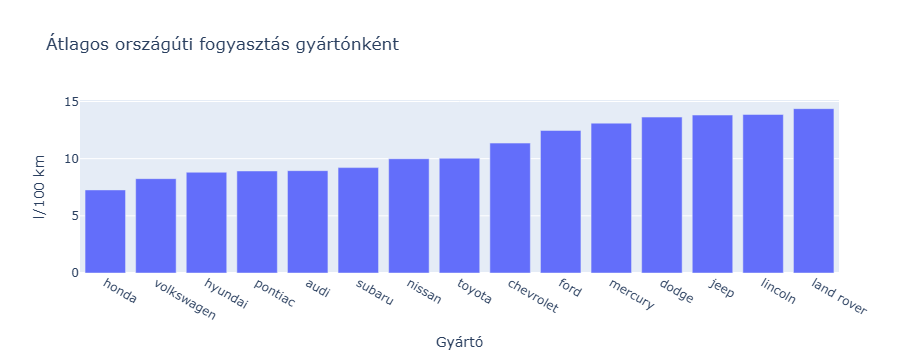

A mintában a legalacsonyabb átlag: honda


In [7]:
gyartok = df.groupby("manufacturer", as_index=False)["orszaguti_l_100km"].mean()
gyartok = gyartok.sort_values("orszaguti_l_100km")
display(gyartok.head(10).round(2))
fig = px.bar(gyartok, x="manufacturer", y="orszaguti_l_100km", title="Átlagos országúti fogyasztás gyártónként", labels={"manufacturer":"Gyártó", "orszaguti_l_100km":"l/100 km"})
fig.show()
print("A mintában a legalacsonyabb átlag:", gyartok.iloc[0]["manufacturer"])

## 2. kérdés: Hogyan függ össze a motorméret és a fogyasztás?
Pontdiagramon minden pont egy megfigyelés. A korreláció megmutatja a lineáris kapcsolat irányát és erősségét.

Korreláció: 0.804


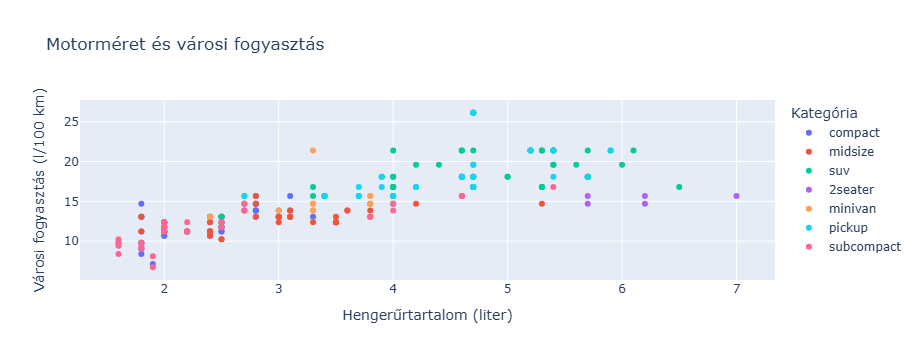

In [8]:
korrelacio = np.corrcoef(df["displ"], df["varosi_l_100km"])[0, 1]
print("Korreláció:", round(korrelacio, 3))
fig = px.scatter(df, x="displ", y="varosi_l_100km", color="class", hover_data=["manufacturer", "model"], title="Motorméret és városi fogyasztás", labels={"displ":"Hengerűrtartalom (liter)", "varosi_l_100km":"Városi fogyasztás (l/100 km)", "class":"Kategória"})
fig.show()

## 3. kérdés: Mennyivel nagyobb a városi fogyasztás az országútinál?
Kiszámoljuk az átlagokat és az autóváltozatonkénti különbség átlagát.

Átlagos városi fogyasztás: 14.84 l/100 km
Átlagos országúti fogyasztás: 10.73 l/100 km
Átlagos különbség: 4.11 l/100 km


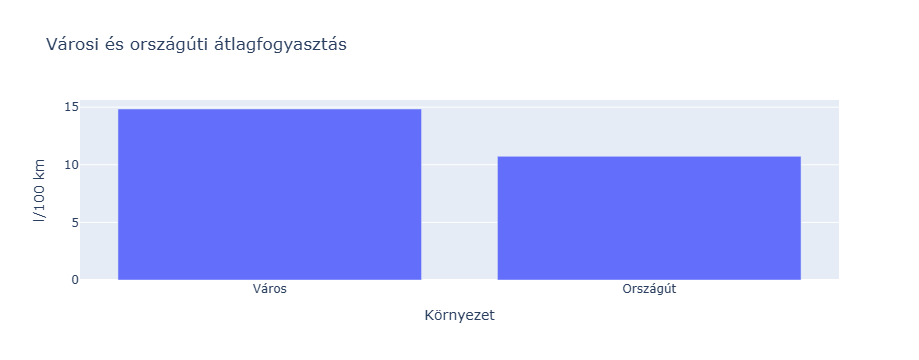

In [9]:
atlag_varos = np.mean(df["varosi_l_100km"])
atlag_orszagut = np.mean(df["orszaguti_l_100km"])
print("Átlagos városi fogyasztás:", round(atlag_varos, 2), "l/100 km")
print("Átlagos országúti fogyasztás:", round(atlag_orszagut, 2), "l/100 km")
print("Átlagos különbség:", round(np.mean(df["kulonbseg_l_100km"]), 2), "l/100 km")
ossz = pd.DataFrame({"Környezet":["Város", "Országút"], "Átlagos fogyasztás":[atlag_varos, atlag_orszagut]})
fig = px.bar(ossz, x="Környezet", y="Átlagos fogyasztás", title="Városi és országúti átlagfogyasztás", labels={"Átlagos fogyasztás":"l/100 km"})
fig.show()

## 4. kérdés: Hogyan változik a fogyasztás a hengerek számával?
A csoportátlagok segítenek a 4, 5, 6 és 8 hengeres változatok összehasonlításában.

,cyl,varosi_l_100km
0,4,11.46
1,5,11.48
2,6,14.69
3,8,19.11


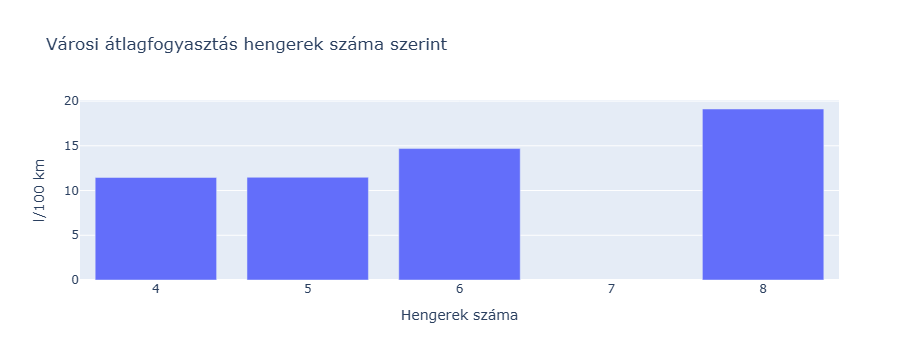

In [10]:
hengerek = df.groupby("cyl", as_index=False)["varosi_l_100km"].mean()
display(hengerek.round(2))
fig = px.bar(hengerek, x="cyl", y="varosi_l_100km", title="Városi átlagfogyasztás hengerek száma szerint", labels={"cyl":"Hengerek száma", "varosi_l_100km":"l/100 km"})
fig.show()

## 5. kérdés: Melyik autókategória a legtakarékosabb?
Az országúti fogyasztást hasonlítjuk össze kategóriánként.

,class,orszaguti_l_100km
1,compact,8.43
5,subcompact,8.62
2,midsize,8.67
0,2seater,9.51
3,minivan,10.62
6,suv,13.30
4,pickup,14.21


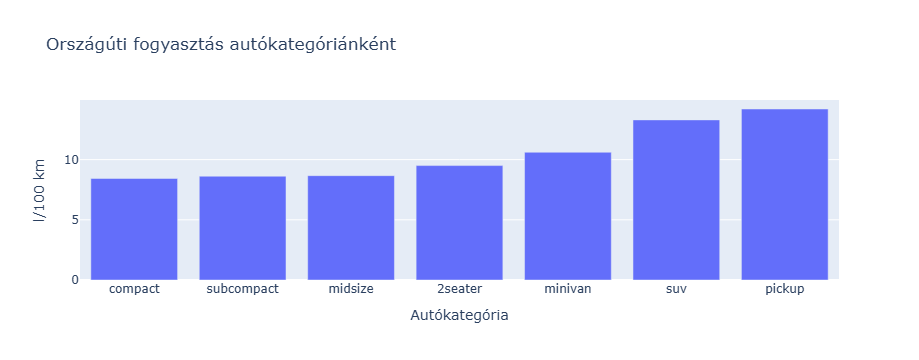

A mintában a legtakarékosabb kategória: compact


In [11]:
kategoriak = df.groupby("class", as_index=False)["orszaguti_l_100km"].mean()
kategoriak = kategoriak.sort_values("orszaguti_l_100km")
display(kategoriak.round(2))
fig = px.bar(kategoriak, x="class", y="orszaguti_l_100km", title="Országúti fogyasztás autókategóriánként", labels={"class":"Autókategória", "orszaguti_l_100km":"l/100 km"})
fig.show()
print("A mintában a legtakarékosabb kategória:", kategoriak.iloc[0]["class"])

## 6. Következtetések
Az alábbi cella az adatokból automatikusan kiírja az öt kérdésre adott rövid válaszokat. Az eredmények csak a vizsgált 234 megfigyelésre vonatkoznak, és az összefüggések önmagukban nem bizonyítanak ok-okozati kapcsolatot.

In [12]:
print("1. A legkisebb országúti átlagfogyasztású gyártó a mintában:", gyartok.iloc[0]["manufacturer"])
print("2. A motorméret és városi fogyasztás korrelációja:", round(korrelacio, 2))
print("3. A városi átlagfogyasztás ennyivel nagyobb:", round(atlag_varos-atlag_orszagut, 2), "l/100 km")
print("4. A legnagyobb városi átlagfogyasztású hengerszám:", int(hengerek.loc[hengerek["varosi_l_100km"].idxmax(), "cyl"]))
print("5. A legalacsonyabb országúti átlagfogyasztású kategória:", kategoriak.iloc[0]["class"])

1. A legkisebb országúti átlagfogyasztású gyártó a mintában: honda
2. A motorméret és városi fogyasztás korrelációja: 0.8
3. A városi átlagfogyasztás ennyivel nagyobb: 4.11 l/100 km
4. A legnagyobb városi átlagfogyasztású hengerszám: 8
5. A legalacsonyabb országúti átlagfogyasztású kategória: compact


## 7. Forrás és korlátok
- Adatforrás: `mpg` adatkészlet a ggplot2-ből, a plotnine Python-csomagban terjesztett CSV alapján.
- Dokumentáció: https://ggplot2.tidyverse.org/reference/mpg.html
- Plotnine forrás: https://github.com/has2k1/plotnine
- Az adatok amerikai mérési rendszerű MPG értékek, nem hivatalos európai WLTP fogyasztási adatok.
- A minta nem reprezentálja a jelenlegi autópiacot.